# KDE numerical foundations for the thesis

Run the two sections in order: the Fourier-error figure and the runtime table.
Raw settings and samples retain their experiment names; every displayed figure
is also exported under `outputs/pdfs/kde_numerics/`.

The classical bandwidth illustration is in
[classical_bandwidth_kde_illustration.ipynb](classical_bandwidth_kde_illustration.ipynb).

Source: [KDE chapter, numerical approximation](../../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex).


## Fourier approximation error


In [10]:
from pathlib import Path
import json
import hashlib
import os
from concurrent.futures import ThreadPoolExecutor, as_completed
from time import perf_counter
import sys

code_directory = next(
    (candidate.resolve()
     for ancestor in (Path.cwd(), *Path.cwd().parents)
     for candidate in (ancestor, ancestor / 'Code' / 'Code_kde')
     if (candidate / 'kde_tools' / 'pdf_export.py').is_file()),
    None,
)
if code_directory is None:
    raise FileNotFoundError('Run this notebook from inside the MASTERARBEIT project.')
if str(code_directory) not in sys.path:
    sys.path.insert(0, str(code_directory))

import matplotlib.pyplot as plt
import numpy as np
from threadpoolctl import threadpool_limits

from kde_tools.density import exact_gaussian_kde_l2_gram
from kde_tools.fourier import (
    FOURIER_L2_METHOD_VERSION,
    gaussian_kde_l2_gram_fourier,
)
from kde_tools.pdf_export import enable_automatic_pdf_saving

notebook_name = 'g_rs_error_vs_k_repeated_samples'
pdf_output_directory = enable_automatic_pdf_saving("kde_numerics")

In [11]:
n = 200
realizations = 200
seed = 20261024
N = 50
h_min, h_max = 0.01, 2.0
frequency_cutoff = 450.0
K_candidates = np.arange(64, 2304 + 1, 16, dtype=int)
highlight_K = 1536
absolute_tolerance = 1e-8
workers = min(4, os.cpu_count() or 1)

samples = np.stack([
    np.random.default_rng(seed + m).normal(size=n)
    for m in range(realizations)
])
bandwidths = np.geomspace(h_min, h_max, N)
settings = {
    'sample_distribution': 'standard_normal', 'realizations': realizations,
    'n': n, 'seed': seed, 'seed_rule': 'seed + zero_based_sample_index',
    'N': N, 'h_min': h_min, 'h_max': h_max, 'bandwidth_grid': 'geometric',
    'frequency_cutoff': frequency_cutoff, 'K_candidates': K_candidates.tolist(),
    'highlight_K': highlight_K, 'absolute_tolerance': absolute_tolerance,
    'K_convention': 'trapezoidal intervals; frequency_points = K + 1',
    'per_sample_error': 'max over all r,s including diagonal of abs(G_exact - G_approx)',
    'summary_curves': ['maximum of per-sample errors'],
    'reference': 'exact_gaussian_kde_l2_gram_float64',
    'method_version': FOURIER_L2_METHOD_VERSION,
    'numpy_version': np.__version__,
}
configuration_id = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:12]
data_directory = code_directory / 'outputs' / 'data' / notebook_name / configuration_id
image_directory = code_directory / 'outputs' / 'images' / notebook_name
data_directory.mkdir(parents=True, exist_ok=True)
image_directory.mkdir(parents=True, exist_ok=True)
(data_directory / 'settings.json').write_text(json.dumps(settings, indent=2) + '\n')
print(f'Configuration {configuration_id}: {realizations} independent samples of size {n}.')
print(f'Omega={frequency_cutoff:g}; {N} geometric bandwidths in [{h_min:g}, {h_max:g}].')
print(f'{len(K_candidates)} K values; up to {workers} calculation threads.')

Configuration 661f8de39b4d: 200 independent samples of size 200.
Omega=450; 50 geometric bandwidths in [0.01, 2].
141 K values; up to 4 calculation threads.


In [12]:
def calculate_one_sample(sample_index):
    current_sample = samples[sample_index]
    reference = exact_gaussian_kde_l2_gram(current_sample, bandwidths)
    local_errors = np.empty(len(K_candidates))
    local_worst_indices = np.empty((len(K_candidates), 2), dtype=int)
    for k_index, K in enumerate(K_candidates):
        approximate = gaussian_kde_l2_gram_fourier(
            current_sample, bandwidths,
            frequency_cutoff=frequency_cutoff,
            frequency_points=int(K) + 1,
        )
        difference = np.abs(approximate - reference)
        r, s = np.unravel_index(np.argmax(difference), difference.shape)
        local_errors[k_index] = difference[r, s]
        local_worst_indices[k_index] = (r, s)
    return sample_index, reference, local_errors, local_worst_indices


# Aggregation choices do not change the per-sample numerical calculation.
calculation_settings = {key: value for key, value in settings.items() if key != 'summary_curves'}
cached_directory = None
for candidate in sorted(data_directory.parent.iterdir()):
    settings_path = candidate / 'settings.json'
    required_paths = [candidate / name for name in (
        'per_sample_results.npz', 'exact_grams.npy', 'samples.npy', 'bandwidths.npy',
    )]
    if not settings_path.is_file() or not all(p.is_file() for p in required_paths):
        continue
    candidate_settings = json.loads(settings_path.read_text())
    candidate_calculation_settings = {
        key: value for key, value in candidate_settings.items() if key != 'summary_curves'
    }
    if candidate_calculation_settings != calculation_settings:
        continue
    if (not np.array_equal(np.load(candidate / 'samples.npy'), samples)
            or not np.array_equal(np.load(candidate / 'bandwidths.npy'), bandwidths)):
        continue
    with np.load(candidate / 'per_sample_results.npz') as cached:
        if (not np.array_equal(cached['K'], K_candidates)
                or cached['errors'].shape != (realizations, len(K_candidates))
                or cached['worst_indices'].shape != (realizations, len(K_candidates), 2)
                or not np.isfinite(cached['errors']).all()
                or np.any(cached['errors'] < 0)):
            continue
        cached_errors = cached['errors'].copy()
        cached_worst_indices = cached['worst_indices'].copy()
    cached_references = np.load(candidate / 'exact_grams.npy')
    if cached_references.shape != (realizations, N, N) or not np.isfinite(cached_references).all():
        continue
    cached_directory = candidate
    break

if cached_directory is not None:
    per_sample_errors = cached_errors
    worst_indices = cached_worst_indices
    exact_grams = cached_references
    elapsed_seconds = 0.0
    calculation_directory = cached_directory
    print(f'Reused all {realizations} verified samples from {cached_directory.name}; no simulations rerun.')
else:
    calculation_directory = data_directory
    np.save(calculation_directory / 'samples.npy', samples)
    np.save(calculation_directory / 'bandwidths.npy', bandwidths)
    per_sample_errors = np.empty((realizations, len(K_candidates)))
    worst_indices = np.empty((realizations, len(K_candidates), 2), dtype=int)
    exact_grams = np.empty((realizations, N, N))
    start = perf_counter()
    with threadpool_limits(limits=1), ThreadPoolExecutor(max_workers=workers) as executor:
        futures = [executor.submit(calculate_one_sample, m) for m in range(realizations)]
        for completed, future in enumerate(as_completed(futures), start=1):
            sample_index, reference, local_errors, local_worst = future.result()
            exact_grams[sample_index] = reference
            per_sample_errors[sample_index] = local_errors
            worst_indices[sample_index] = local_worst
            if completed % 10 == 0 or completed == realizations:
                print(f'Completed {completed}/{realizations} samples ({perf_counter() - start:.1f} s).', flush=True)
    elapsed_seconds = perf_counter() - start
    np.save(data_directory / 'exact_grams.npy', exact_grams)
    np.savez_compressed(
        data_directory / 'per_sample_results.npz',
        K=K_candidates, errors=per_sample_errors, worst_indices=worst_indices,
    )
# Summary views point to one verified numerical cache instead of copying it.
(data_directory / 'cache_reference.json').write_text(
    json.dumps({'relative_directory': os.path.relpath(calculation_directory, data_directory)}, indent=2) + '\n'
)


Reused all 200 verified samples from 661f8de39b4d; no simulations rerun.


32

In [13]:
maximum_errors = per_sample_errors.max(axis=0)
worst_sample_indices = per_sample_errors.argmax(axis=0)
exceeding_counts = (per_sample_errors > absolute_tolerance).sum(axis=0)
summary_table = np.column_stack([
    K_candidates, maximum_errors, worst_sample_indices, exceeding_counts,
])
np.savetxt(
    data_directory / 'g_rs_error_vs_k_maximum_summary.csv', summary_table,
    delimiter=',', comments='',
    header='K,max_E_K,worst_sample_zero_based,samples_exceeding_tolerance',
    fmt=['%d', '%.17g', '%d', '%d'],
)
highlight_index = int(np.flatnonzero(K_candidates == highlight_K)[0])
passing_maximum = np.flatnonzero(maximum_errors <= absolute_tolerance)
report = {
    'configuration_id': configuration_id,
    'n': n, 'realizations': realizations, 'N': N, 'frequency_cutoff': frequency_cutoff,
    'absolute_tolerance': absolute_tolerance,
    'first_tested_K_max_below_tolerance': int(K_candidates[passing_maximum[0]]) if len(passing_maximum) else None,
    'highlight_K': highlight_K,
    'max_error_at_highlight_K': float(maximum_errors[highlight_index]),
    'samples_exceeding_tolerance_at_highlight_K': int(exceeding_counts[highlight_index]),
    'largest_tested_K': int(K_candidates[-1]),
    'max_error_at_largest_K': float(maximum_errors[-1]),
    'calculation_seconds_this_run': elapsed_seconds, 'workers': workers,
    'reused_cache_configuration': cached_directory.name if cached_directory is not None else None,
    'empirical_scope': 'maximum over 200 samples of size 200 and all pairs of 50 bandwidths including diagonal',
}
(data_directory / 'report.json').write_text(json.dumps(report, indent=2) + '\n')
print(f'First tested K with maximum E_K <= {absolute_tolerance:g}: {report["first_tested_K_max_below_tolerance"]}')
print(f'At K={highlight_K}: maximum error={maximum_errors[highlight_index]:.8e}.')
print(f'Samples above the target at K={highlight_K}: {exceeding_counts[highlight_index]}/{realizations}.')

First tested K with maximum E_K <= 1e-08: 1376
At K=1536: maximum error=1.58663055e-10.
Samples above the target at K=1536: 0/200.


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/kde_numerics/001_maximum_error_over_200_samples_at_omega_450_n_200_n_50_h_in_0_01_2_geometric_ban.pdf


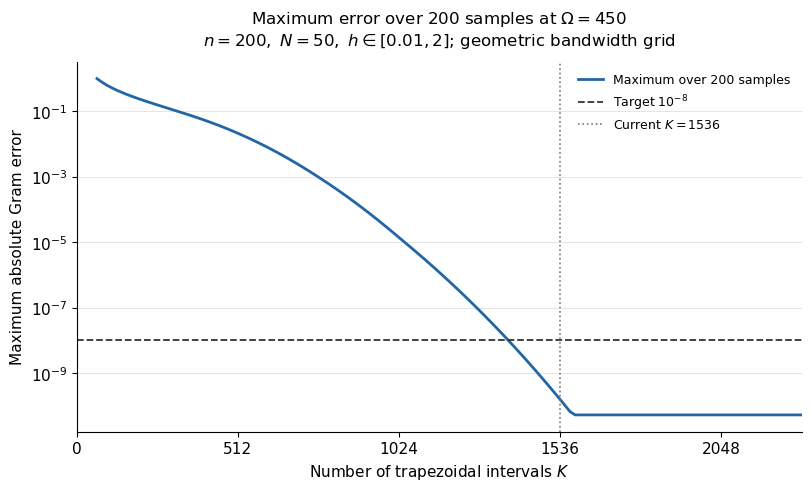

In [14]:
with plt.rc_context({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False, 'pdf.fonttype': 42,
}):
    fig, ax = plt.subplots(figsize=(8.0, 4.8), layout='constrained')
    ax.plot(K_candidates, maximum_errors, color='#2266a5', linewidth=2.0,
            label=rf'Maximum over {realizations} samples')
    ax.axhline(absolute_tolerance, color='#333333', linestyle='--', linewidth=1.3,
               label=r'Target $10^{-8}$')
    ax.axvline(highlight_K, color='#777777', linestyle=':', linewidth=1.2,
               label=rf'Current $K={highlight_K}$')
    ax.set_yscale('log')
    ax.set_xlim(0, K_candidates[-1])
    ax.set_xticks([0, 512, 1024, 1536, 2048])
    ax.set_xlabel(r'Number of trapezoidal intervals $K$')
    ax.set_ylabel('Maximum absolute Gram error')
    ax.set_title(
        rf'Maximum error over {realizations} samples at $\Omega=450$' + '\n'
        + rf'$n={n},\ N={N},\ h\in[{h_min:g},{h_max:g}]$; geometric bandwidth grid',
        fontsize=12, pad=12,
    )
    ax.grid(axis='y', which='major', color='#e5e5e5', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.legend(loc='upper right', frameon=False, fontsize=9)
    png_path = image_directory / 'g_rs_error_vs_k_maximum.png'
    fig.savefig(png_path, dpi=200, bbox_inches='tight')
    plt.show()  # Also saves the PDF through kde_tools.pdf_export.
from kde_tools.thesis_exports import copy_thesis_pdf
if n == 200 and N == 50 and realizations == 200:
    copy_thesis_pdf(pdf_output_directory, "g_rs_error_vs_k_repeated_samples",
        "001_maximum_error_over_200_samples_at_omega_450_n_200_n_50_h_in_0_01_2_geometric_ban.pdf")


## Exact versus Fourier runtime table


In [15]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter, get_clock_info
import csv
import hashlib
import inspect
import io
import json
import os
import platform
import subprocess
import sys
import uuid

# Set before importing numerical libraries in a fresh kernel.
thread_environment_keys = (
    'VECLIB_MAXIMUM_THREADS', 'OPENBLAS_NUM_THREADS',
    'OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'BLIS_NUM_THREADS',
)
for variable in thread_environment_keys:
    os.environ[variable] = '1'

code_directory = next(
    (candidate.resolve()
     for ancestor in (Path.cwd(), *Path.cwd().parents)
     for candidate in (ancestor, ancestor / 'Code' / 'Code_kde')
     if (candidate / 'kde_tools' / 'pdf_export.py').is_file()),
    None,
)
if code_directory is None:
    raise FileNotFoundError('Run this notebook from inside the MASTERARBEIT project.')
if str(code_directory) not in sys.path:
    sys.path.insert(0, str(code_directory))

import numpy as np
import scipy
from IPython.display import Markdown, display
from threadpoolctl import threadpool_info, threadpool_limits

from kde_tools.density import exact_gaussian_kde_l2_gram
from kde_tools.fourier import (
    DEFAULT_FREQUENCY_CUTOFF,
    DEFAULT_FREQUENCY_INTERVALS,
    FOURIER_L2_METHOD_VERSION,
    gaussian_kde_l2_gram_fourier,
)
from kde_tools.pdf_export import enable_automatic_pdf_saving

notebook_name = 'g_rs_runtime_comparison'
pdf_output_directory = enable_automatic_pdf_saving("kde_numerics")

In [16]:
n = 200
realizations = 100
N = 50
h_min, h_max = 0.01, 2.0
frequency_cutoff = DEFAULT_FREQUENCY_CUTOFF
K = DEFAULT_FREQUENCY_INTERVALS
seed = 2026102600
warmup_calls_per_method = 3
absolute_tolerance = 1e-8

bandwidths = np.geomspace(h_min, h_max, N)
samples = np.stack([
    np.random.default_rng(seed + sample_index).normal(size=n)
    for sample_index in range(realizations)
])
warmup_sample = np.random.default_rng(seed + 1000000).normal(size=n)
source_paths = {
    'exact': Path(inspect.getfile(exact_gaussian_kde_l2_gram)),
    'fourier': Path(inspect.getfile(gaussian_kde_l2_gram_fourier)),
}
settings = {
    'experiment_version': 'paired_full_gram_runtime_v1',
    'sample_distribution': 'standard_normal',
    'n': n, 'realizations': realizations, 'N': N,
    'h_min': h_min, 'h_max': h_max, 'bandwidth_grid': 'geometric',
    'seed': seed, 'seed_rule': 'seed + zero_based_sample_index',
    'warmup_seed': seed + 1000000,
    'frequency_cutoff': float(frequency_cutoff), 'K': int(K),
    'frequency_points': int(K) + 1,
    'K_convention': 'number of trapezoidal intervals',
    'method_version': FOURIER_L2_METHOD_VERSION,
    'timer': 'time.perf_counter',
    'timing_scope': 'one full Gram helper call; no sampling, warm-up, validation or I/O',
    'warmup_calls_per_method': warmup_calls_per_method,
    'order': 'exact first for even zero-based indices; Fourier first for odd indices',
    'parallel_samples': False, 'requested_numerical_library_threads': 1,
    'maximum_error': 'maximum absolute difference over all samples and all ordered bandwidth pairs, including diagonal',
    'absolute_tolerance': absolute_tolerance,
    'numpy_version': np.__version__, 'scipy_version': scipy.__version__,
    'source_sha256': {
        key: hashlib.sha256(path.read_bytes()).hexdigest()
        for key, path in source_paths.items()
    },
    'sample_sha256': hashlib.sha256(samples.tobytes()).hexdigest(),
    'bandwidth_sha256': hashlib.sha256(bandwidths.tobytes()).hexdigest(),
}
configuration_id = hashlib.sha256(
    json.dumps(settings, sort_keys=True).encode()
).hexdigest()[:12]
run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ') + '_' + uuid.uuid4().hex[:6]
data_directory = code_directory / 'outputs' / 'data' / notebook_name / configuration_id / run_id
data_directory.mkdir(parents=True, exist_ok=False)
(data_directory / 'settings.json').write_text(json.dumps(settings, indent=2) + '\n')
np.save(data_directory / 'samples.npy', samples)
np.save(data_directory / 'bandwidths.npy', bandwidths)
print(f'{realizations} samples of size {n}; {N} bandwidths; Omega={frequency_cutoff:g}; K={K}.')
print(f'Results: {data_directory}')

100 samples of size 200; 50 bandwidths; Omega=450; K=1536.
Results: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/g_rs_runtime_comparison/1a13a92c437d/20261029T214514049437Z_c252e9


In [17]:
exact_seconds = np.empty(realizations)
fourier_seconds = np.empty(realizations)
exact_grams = np.empty((realizations, N, N))
fourier_grams = np.empty_like(exact_grams)
per_sample_max_errors = np.empty(realizations)
worst_indices = np.empty((realizations, 2), dtype=int)

# No other sample calculations run concurrently with these measurements.
with threadpool_limits(limits=1):
    for _ in range(warmup_calls_per_method):
        exact_gaussian_kde_l2_gram(warmup_sample, bandwidths)
        gaussian_kde_l2_gram_fourier(
            warmup_sample, bandwidths,
            frequency_cutoff=frequency_cutoff, frequency_points=int(K) + 1,
        )
    active_threadpools = threadpool_info()
    experiment_start = perf_counter()
    for sample_index, current_sample in enumerate(samples):
        method_order = ('exact', 'fourier') if sample_index % 2 == 0 else ('fourier', 'exact')
        for method in method_order:
            if method == 'exact':
                start = perf_counter()
                current_exact = exact_gaussian_kde_l2_gram(current_sample, bandwidths)
                duration = perf_counter() - start
                exact_seconds[sample_index] = duration
                exact_grams[sample_index] = current_exact
            else:
                start = perf_counter()
                current_fourier = gaussian_kde_l2_gram_fourier(
                    current_sample, bandwidths,
                    frequency_cutoff=frequency_cutoff, frequency_points=int(K) + 1,
                )
                duration = perf_counter() - start
                fourier_seconds[sample_index] = duration
                fourier_grams[sample_index] = current_fourier
        difference = np.abs(current_fourier - current_exact)
        r, s = np.unravel_index(np.argmax(difference), difference.shape)
        worst_indices[sample_index] = (r, s)
        per_sample_max_errors[sample_index] = difference[r, s]
        if (sample_index + 1) % 10 == 0:
            print(f'Completed {sample_index + 1}/{realizations} samples '
                  f'({perf_counter() - experiment_start:.1f} s).', flush=True)
    experiment_seconds = perf_counter() - experiment_start

np.savez_compressed(
    data_directory / 'per_sample_results.npz',
    exact_seconds=exact_seconds, fourier_seconds=fourier_seconds,
    maximum_absolute_errors=per_sample_max_errors, worst_indices=worst_indices,
    exact_grams=exact_grams, fourier_grams=fourier_grams,
)
with (data_directory / 'per_sample_results.csv').open('w', newline='') as handle:
    writer = csv.writer(handle)
    writer.writerow([
        'sample_l_one_based', 'seed', 'first_method', 'exact_seconds',
        'fourier_seconds', 'maximum_absolute_error', 'worst_r_zero_based',
        'worst_s_zero_based', 'h_r', 'h_s',
    ])
    for sample_index in range(realizations):
        r, s = worst_indices[sample_index]
        writer.writerow([
            sample_index + 1, seed + sample_index,
            'exact' if sample_index % 2 == 0 else 'fourier',
            exact_seconds[sample_index], fourier_seconds[sample_index],
            per_sample_max_errors[sample_index], int(r), int(s),
            bandwidths[r], bandwidths[s],
        ])

Completed 10/100 samples (2.9 s).
Completed 20/100 samples (5.8 s).
Completed 30/100 samples (9.0 s).
Completed 40/100 samples (11.9 s).
Completed 50/100 samples (14.8 s).
Completed 60/100 samples (17.7 s).
Completed 70/100 samples (20.6 s).
Completed 80/100 samples (23.4 s).
Completed 90/100 samples (26.2 s).
Completed 100/100 samples (29.5 s).


In [18]:
# Verify the saved measurements and all entries before writing the table.
assert exact_grams.shape == fourier_grams.shape == (realizations, N, N)
assert np.isfinite(exact_grams).all() and np.isfinite(fourier_grams).all()
assert np.isfinite(exact_seconds).all() and np.all(exact_seconds > 0)
assert np.isfinite(fourier_seconds).all() and np.all(fourier_seconds > 0)
assert np.array_equal(exact_grams, exact_grams.transpose(0, 2, 1))
assert np.allclose(fourier_grams, fourier_grams.transpose(0, 2, 1), rtol=0, atol=1e-14)
all_errors = np.abs(fourier_grams - exact_grams)
assert np.array_equal(per_sample_max_errors, all_errors.max(axis=(1, 2)))

worst_l, worst_r, worst_s = np.unravel_index(np.argmax(all_errors), all_errors.shape)
maximum_error = float(all_errors[worst_l, worst_r, worst_s])
mean_exact_seconds = float(exact_seconds.mean())
mean_fourier_seconds = float(fourier_seconds.mean())
speedup = mean_exact_seconds / mean_fourier_seconds

def timing_statistics(values):
    return {
        'mean_seconds': float(values.mean()),
        'standard_deviation_seconds': float(values.std(ddof=1)),
        'median_seconds': float(np.median(values)),
        'minimum_seconds': float(values.min()),
        'maximum_seconds': float(values.max()),
        'total_seconds': float(values.sum()),
    }

cpu_model = platform.processor()
if sys.platform == 'darwin':
    cpu_query = subprocess.run(
        ['sysctl', '-n', 'machdep.cpu.brand_string'],
        capture_output=True, text=True, check=False,
    )
    if cpu_query.returncode == 0:
        cpu_model = cpu_query.stdout.strip()

report = {
    **settings, 'configuration_id': configuration_id, 'run_id': run_id,
    'completed_utc': datetime.now(timezone.utc).isoformat(),
    'platform': platform.platform(), 'machine': platform.machine(),
    'cpu_model': cpu_model, 'logical_cpu_count': os.cpu_count(),
    'python_version': sys.version, 'python_executable': sys.executable,
    'clock_info': vars(get_clock_info('perf_counter')),
    'thread_environment': {key: os.environ.get(key) for key in thread_environment_keys},
    'detected_threadpools_during_timing': active_threadpools,
    'exact': timing_statistics(exact_seconds),
    'fourier': timing_statistics(fourier_seconds),
    'speedup_ratio_of_mean_times': speedup,
    'maximum_absolute_error': maximum_error,
    'samples_exceeding_tolerance': int(np.count_nonzero(per_sample_max_errors > absolute_tolerance)),
    'worst_case': {
        'sample_l_one_based': int(worst_l) + 1, 'seed': seed + int(worst_l),
        'r_zero_based': int(worst_r), 's_zero_based': int(worst_s),
        'h_r': float(bandwidths[worst_r]), 'h_s': float(bandwidths[worst_s]),
        'exact_value': float(exact_grams[worst_l, worst_r, worst_s]),
        'fourier_value': float(fourier_grams[worst_l, worst_r, worst_s]),
    },
    'ordered_pairs_per_sample_including_diagonal': N * N,
    'unique_symmetric_pairs_per_sample_including_diagonal': N * (N + 1) // 2,
    'checked_entries_total': realizations * N * N,
    'experiment_elapsed_seconds_excluding_warmup_and_exports': experiment_seconds,
    'timing_order_counts': {'exact_first': (realizations + 1) // 2, 'fourier_first': realizations // 2},
    'validation': {
        'all_entries_finite': True, 'all_times_finite_and_positive': True,
        'exact_matrices_symmetric': True, 'fourier_matrices_symmetric_to_1e_minus_14': True,
        'stored_per_sample_maxima_match_full_matrices': True,
    },
}
(data_directory / 'report.json').write_text(json.dumps(report, indent=2) + '\n')
np_config_buffer = io.StringIO()
from contextlib import redirect_stdout
with redirect_stdout(np_config_buffer):
    np.show_config()
(data_directory / 'numpy_configuration.txt').write_text(np_config_buffer.getvalue())

with (data_directory / 'summary.csv').open('w', newline='') as handle:
    writer = csv.writer(handle)
    writer.writerow(['method', 'mean_seconds', 'mean_milliseconds', 'standard_deviation_seconds', 'maximum_absolute_error_vs_exact'])
    writer.writerow(['Exact Gaussian formula', mean_exact_seconds, 1000 * mean_exact_seconds, report['exact']['standard_deviation_seconds'], ''])
    writer.writerow(['Fourier approximation', mean_fourier_seconds, 1000 * mean_fourier_seconds, report['fourier']['standard_deviation_seconds'], maximum_error])

summary_markdown = (
    '| Method | Mean time per complete matrix (ms) | Maximum absolute error |\n'
    '| --- | ---: | ---: |\n'
    f'| Exact Gaussian formula | {1000 * mean_exact_seconds:.3f} | Reference |\n'
    f'| Fourier approximation | {1000 * mean_fourier_seconds:.3f} | {maximum_error:.3e} |\n'
)
summary_note = (
    f'\n100 standard-normal samples, n=200; N=50 geometric bandwidths in [0.01, 2]; '
    f'Omega={frequency_cutoff:g}, K={K} intervals. '
    f'The Fourier implementation is {speedup:.2f} times faster by the ratio of mean times. '
    f'The error is the maximum over all {realizations * N * N:,} matrix entries, including diagonals. '
    f'Measured on {cpu_model} ({platform.system()} {platform.release()}); timings are machine dependent.\n'
)
(data_directory / 'summary.md').write_text(summary_markdown + summary_note)

mantissa, exponent = f'{maximum_error:.3e}'.split('e')
latex_error = rf'${mantissa}\times10^{{{int(exponent)}}}$'
latex_table = '\n'.join([
    r'\begin{table}[htbp]', r'\centering', r'\begin{tabular}{lrr}', r'\hline',
    r'Method & Mean time (ms) & Maximum absolute error \\', r'\hline',
    f'Exact Gaussian formula & {1000 * mean_exact_seconds:.3f} & --- ' + r'\\',
    f'Fourier approximation & {1000 * mean_fourier_seconds:.3f} & {latex_error} ' + r'\\',
    r'\hline', r'\end{tabular}',
    rf'\caption{{Runtime comparison over $M={realizations}$ standard-normal samples of size $n={n}$, '
    rf'using $N={N}$ geometrically spaced bandwidths in $[0.01,2]$, '
    rf'$\Omega={frequency_cutoff:g}$ and $K={K}$ trapezoidal intervals. '
    r'Times are arithmetic means for complete Gram-matrix calculations. '
    r'The maximum absolute error is taken over all samples and bandwidth pairs, including diagonal entries, '
    r'with the float64 analytic calculation as reference.}',
    r'\label{tab:exact_fourier_gram_runtime}', r'\end{table}', '',
])
(data_directory / 'runtime_comparison_table.tex').write_text(latex_table)
(code_directory / 'outputs' / 'data' / notebook_name / 'latest_run.json').write_text(
    json.dumps({'relative_directory': str(data_directory.relative_to(code_directory)),
                'configuration_id': configuration_id, 'run_id': run_id}, indent=2) + '\n'
)
display(Markdown(summary_markdown + summary_note))
print(f'Worst error: {maximum_error:.12e}; sample l={worst_l + 1}, h={bandwidths[worst_r]:g}, s={bandwidths[worst_s]:g}.')
print(f'Samples above {absolute_tolerance:g}: {report["samples_exceeding_tolerance"]}/{realizations}.')
print(f'LaTeX table: {data_directory / "runtime_comparison_table.tex"}')

| Method | Mean time per complete matrix (ms) | Maximum absolute error |
| --- | ---: | ---: |
| Exact Gaussian formula | 284.126 | Reference |
| Fourier approximation | 10.450 | 9.182e-11 |

100 standard-normal samples, n=200; N=50 geometric bandwidths in [0.01, 2]; Omega=450, K=1536 intervals. The Fourier implementation is 27.19 times faster by the ratio of mean times. The error is the maximum over all 250,000 matrix entries, including diagonals. Measured on Apple M1 (Darwin 25.5.0); timings are machine dependent.


Worst error: 9.181809479397e-11; sample l=44, h=2, s=2.
Samples above 1e-08: 0/100.
LaTeX table: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/g_rs_runtime_comparison/1a13a92c437d/20261029T214514049437Z_c252e9/runtime_comparison_table.tex
